# EXERCISE 1: Chapter 1
## Instantaneous and Cumulative Chain Length Distribution

### 1) Monomer evolution 
PSSA assuming the characteristic time for termination is much shorter than for propagation. The active radical concentration reaches steady state instantly (also f=0.5):

   $$\frac{dR^\bullet}{dt}=2 fk_d[I_2]-(k_{tc}+k_{td})R^{\bullet2}$$
   $$\Rightarrow [R^\bullet] = \sqrt{\frac{k_d [I_2]}{k_t}}$$
   
   The batch reactor mass balances track initiator and monomer depletion:
   
   $$\frac{d[I_2]}{dt} = -k_d [I_2]$$
   $$\frac{d[M]}{dt} = -R_p = -k_p [M] [R^\bullet]$$
   
   As conversion $X$ increases, the polymer weight fraction $w_p$ rises, restricting diffusion. We continuously update $k_p$ and $k_t$ (gel/Trommsdorff effect) to capture auto-acceleration:

   $$k_p = \frac{1}{\frac{1}{k_{p,0}} + \frac{\exp(C_\eta w_p)}{k_{pD,0}}}$$
   $$k_t = \frac{1}{\frac{1}{k_{t,0}} + \frac{\exp(C_\eta w_p)}{k_{tD,0}}} + C_{RD} k_p (1 - w_p)$$

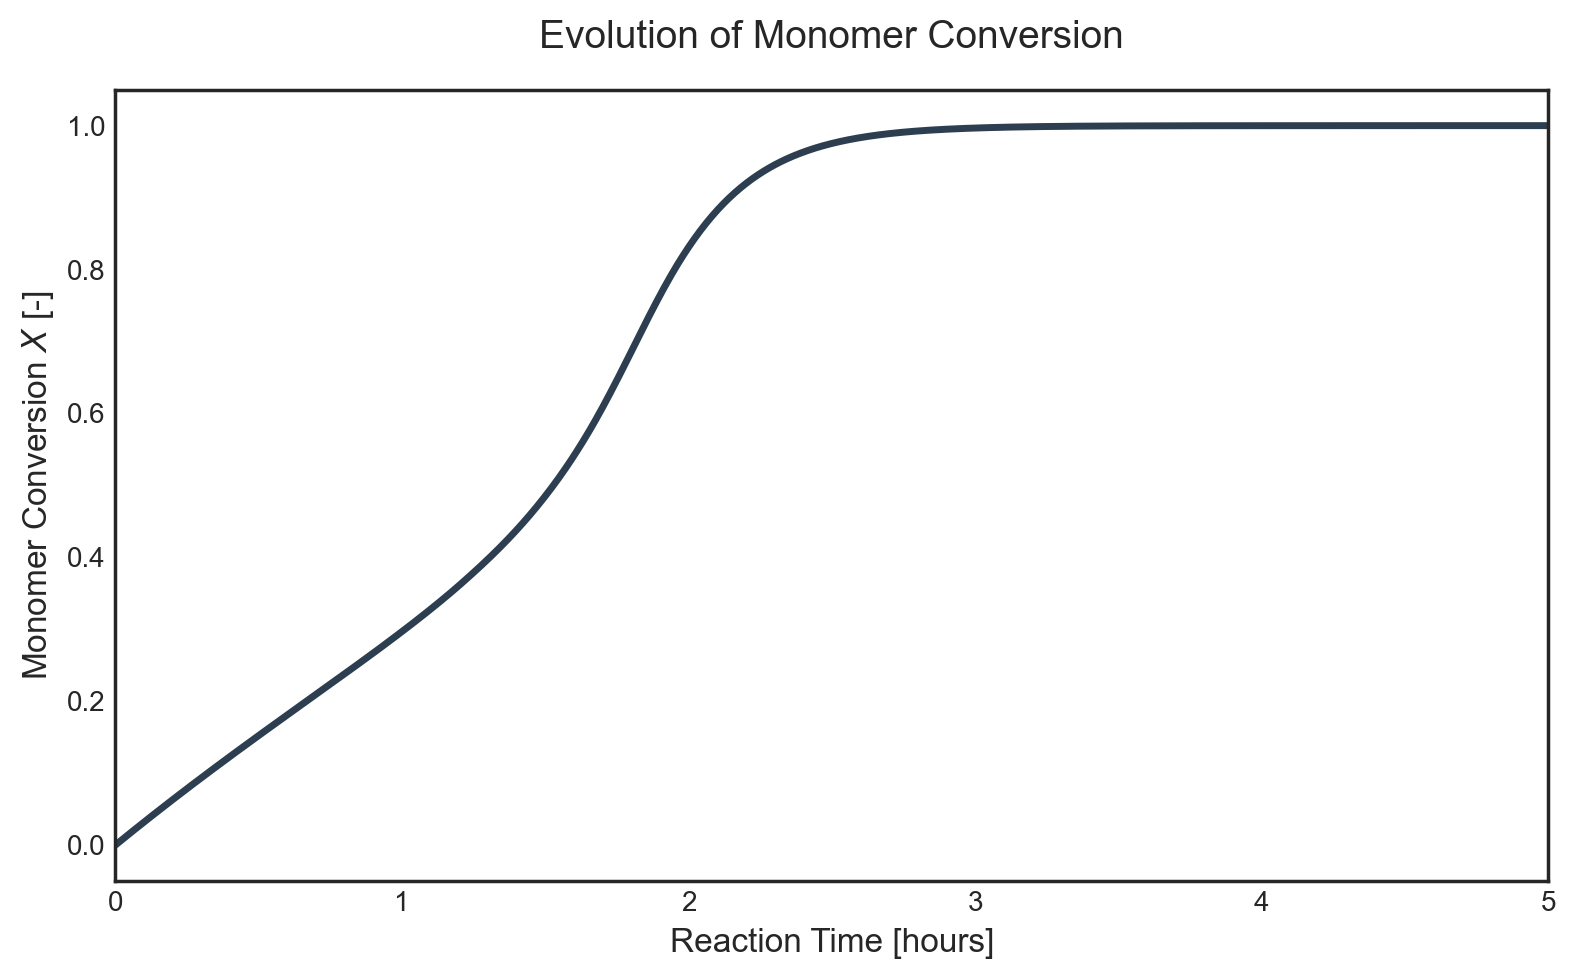

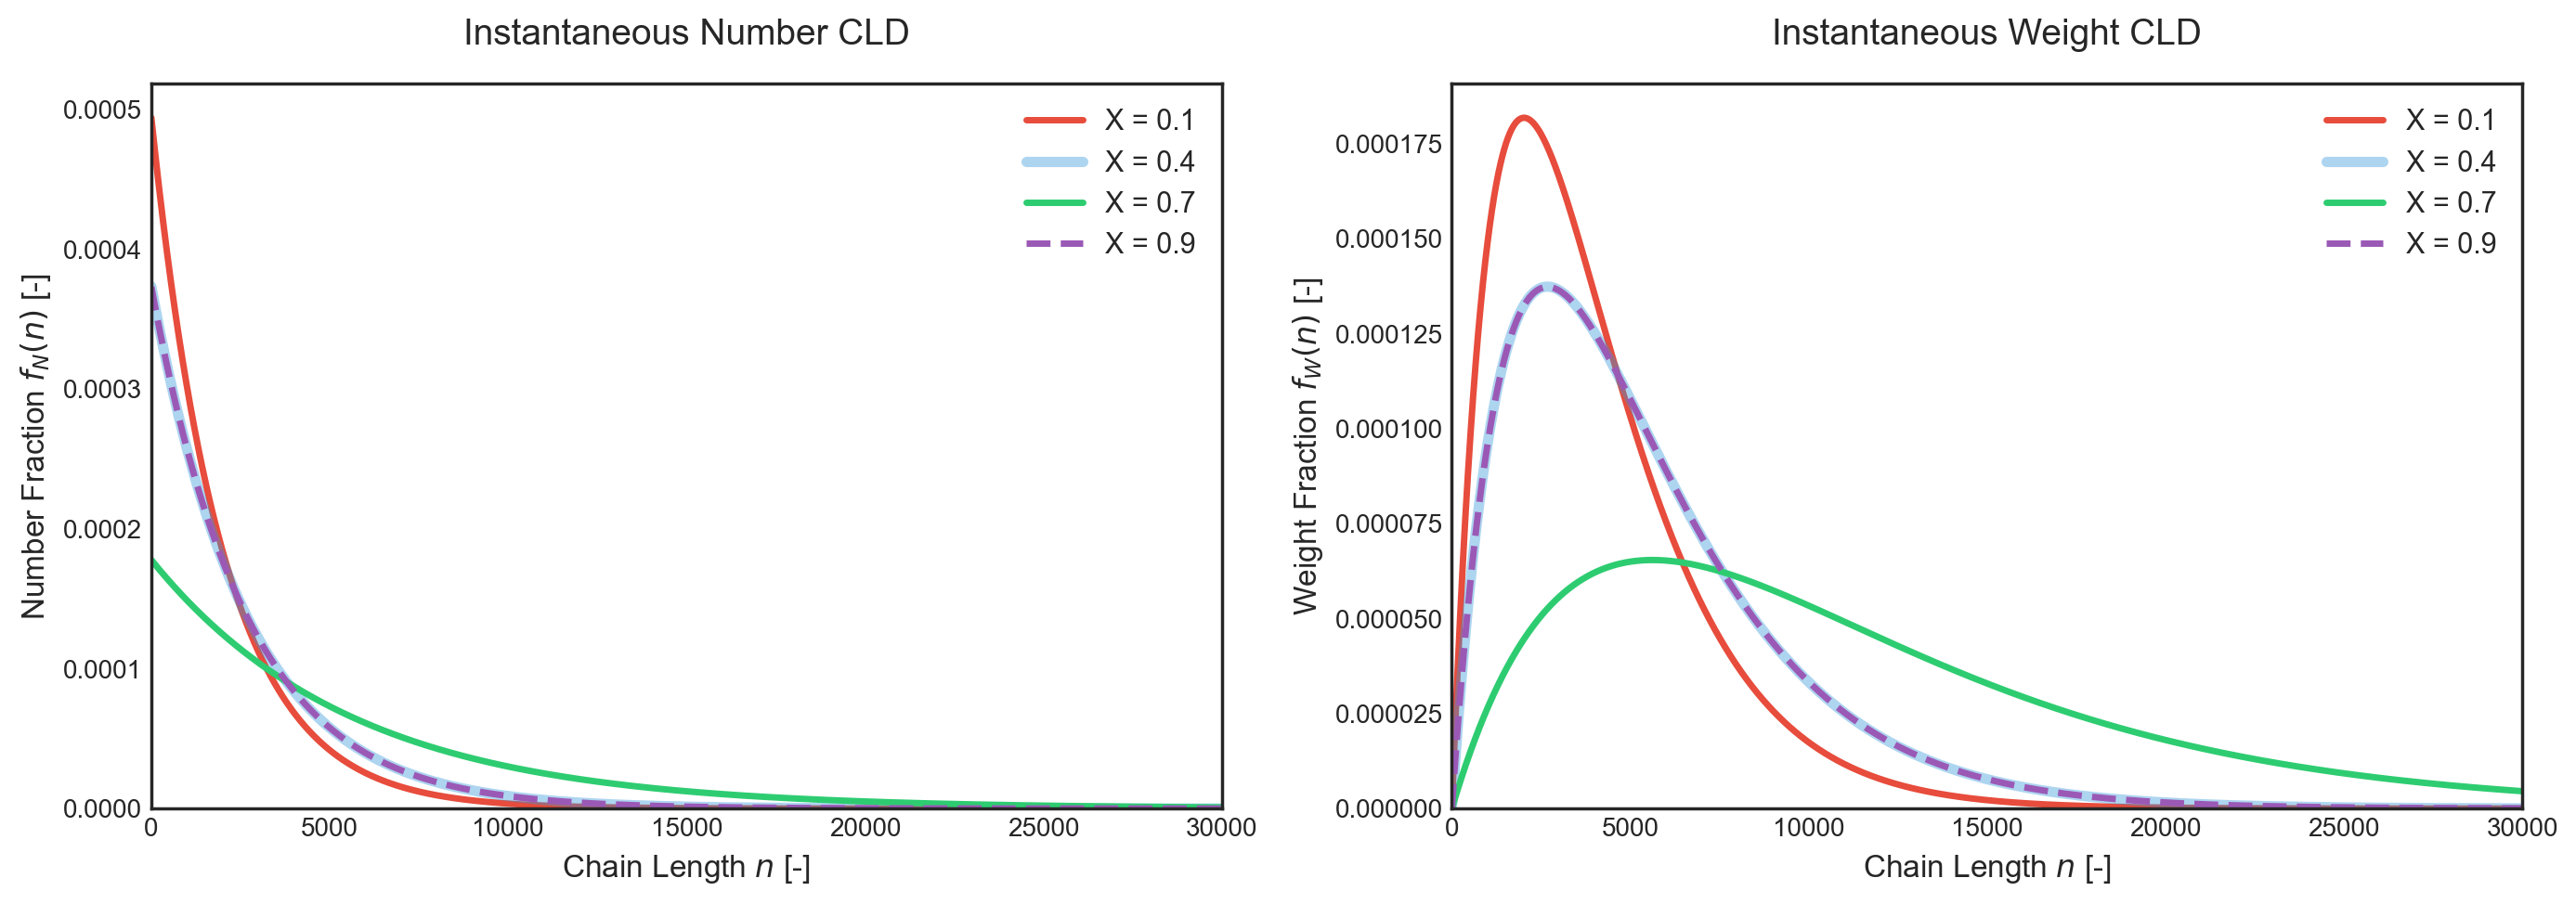

In [26]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
import matplotlib as mpl
%config InlineBackend.figure_format = 'retina'

# Constants & Parameters 
M_m_M = 100.0   # g/mol
M_m_S = 78.0    
M_m_I = 164.0   
rho_M = 0.94    # kg/L
rho_S = 0.88    
f = 0.5
k_d = 6.77e-6   # s^-1
k_t0 = 9.2e6    # L/(mol s)
k_tD0 = 5.0e8   
k_p0 = 620.0    
k_pD0 = 2.0e11  

C_eta = 25.0 
C_RD = 180.0

# Init Conditions 
M_0 = 4.7 # mol/L
w_I_0 = 0.01 # relative to monomer mass

#  per 1L of mixture
mass_M_0 = M_0 * M_m_M                # g/L
vol_M_0 = (mass_M_0 / 1000) / rho_M   # L
vol_S_0 = 1.0 - vol_M_0               # L 
mass_S_0 = vol_S_0 * rho_S * 1000     # g
mass_total = mass_M_0 + mass_S_0      # Total mixture mass per Liter

# Initiator initial concentration
I_0 = (w_I_0 * mass_M_0) / M_m_I      # mol/L

# Kinetic Functions
def calc_kinetics(X, apply_diffusion=True):
    """Calculates kp and kt.
    As conversion (X) goes up, the mixture gets more visquous, lowering kp and kt"""
    if not apply_diffusion:
        return k_p0, k_t0
    
    w_p = (X * mass_M_0) / mass_total
    k_p = 1.0 / ((1.0 / k_p0) + (np.exp(C_eta * w_p) / k_pD0))
    k_t = 1.0 / ((1.0 / k_t0) + (np.exp(C_eta * w_p) / k_tD0)) + C_RD * k_p * (1.0 - w_p)
    return k_p, k_t

def reactor_ode(t, y, apply_diffusion):
    """ODEs.
    y[0] is Initiator concentration [I]
    y[1] is Monomer concentration [M]"""
    I, M = y
    X = max(0.0, (M_0 - M) / M_0) # Calculate current conversion. max(0, ...) prevents negative values due to solver overshoots
    
    k_p, k_t = calc_kinetics(X, apply_diffusion)
    R_dot = np.sqrt((2 * f * k_d * I) / k_t) if k_t > 0 else 0
    
    dI_dt = -k_d * I
    dM_dt = -k_p * M * R_dot
    
    return [dI_dt, dM_dt]

# ODE Integration with Events for Specific Conversions 
def make_event(target_X):
    """
    Creates a function that tracks when the ODE solver hits a specific conversion.
    The solver checks this function at every time step. When it crosses 0, it logs the data.
    """
    def event(t, y, apply_diff):
        return ((M_0 - y[1]) / M_0) - target_X
    event.direction = 1 #tells the solver to only trigger when crossing from negative to positive (increase in conversion and prvents fluctuation errors)
    return event

target_conversions = [0.10, 0.40, 0.70, 0.90]
events = [make_event(x) for x in target_conversions]

t_span = (0, 10*3600)
y0 = [I_0, M_0]
# Create a dense time array for smooth output (otherwise would get a clunky solution due to time skipping)
t_smooth = np.linspace(0, 10 * 3600, 2000)


sol_diff = solve_ivp(reactor_ode, t_span, y0, args=(True,), method='Radau', 
                     dense_output=True, events=events, t_eval=t_smooth) 

"""" We use the 'Radau' method because this ODE system becomes stiff
This stiffness is driven by the different time scales of the reactions 
(fast radicals vs. slow initiator decay) and the spike in the 
reaction rate during the gel effect. Standard solvers (like RK45) often 
fail or take too long to resolve these sudden mathematical cliffs."""



# PLOTTING 
import matplotlib as mpl

# --- Apply Global Aesthetic Improvements ---
plt.style.use('seaborn-v0_8-white')
mpl.rcParams['axes.spines.top'] = True     # Restored the top border
mpl.rcParams['axes.spines.right'] = True   # Restored the right border
mpl.rcParams['axes.labelsize'] = 12
mpl.rcParams['axes.titlesize'] = 14
mpl.rcParams['xtick.labelsize'] = 10
mpl.rcParams['ytick.labelsize'] = 10
mpl.rcParams['legend.fontsize'] = 11

# Plot 1: Conversion vs Time 

X_diff = (M_0 - sol_diff.y[1]) / M_0

fig1, ax1 = plt.subplots(figsize=(8, 5))
ax1.plot(sol_diff.t / 3600, X_diff, color='#2c3e50', linewidth=2.5) # Dark navy line
ax1.set_xlabel('Reaction Time [hours]')
ax1.set_ylabel('Monomer Conversion $X$ [-]')
ax1.set_title('Evolution of Monomer Conversion', pad=15)
ax1.grid(False) # Grid removed
ax1.set_xlim(0, 5)

plt.tight_layout()
plt.show()


# Plot 2 & 3: Instantaneous CLD at target conversions

n_chain = np.arange(1, 30001)

fig2, (ax2_1, ax2_2) = plt.subplots(1, 2, figsize=(14, 5))

# Use a distinct, modern color palette
colors = ['#e74c3c', '#3498db', '#2ecc71', '#9b59b6'] 

for i, (target_X, color) in enumerate(zip(target_conversions, colors)):
    # Extract concentrations at the exact time the target conversion was hit
    I_val = sol_diff.y_events[i][0][0]
    M_val = sol_diff.y_events[i][0][1]
    
    k_p, k_t = calc_kinetics(target_X, apply_diffusion=True)
    R_dot = np.sqrt((2 * f * k_d * I_val) / k_t)
    
    # Task 1 condition: Termination by disproportionation entirely
    beta = 0 
    gamma = (k_t * R_dot) / (k_p * M_val)
    alpha = beta + gamma
    
    # Distributions
    n_N = 1 / gamma
    f_N = (alpha / (1 + alpha)**n_chain) 
    f_W = (n_chain * f_N) / n_N
    
    # Adjust linestyles to reveal overlapping curves at X=0.4 and X=0.9
    if target_X == 0.40:
        ax2_1.plot(n_chain, f_N, label=f'X = {target_X}', linewidth=4, alpha=0.4, color=color)
        ax2_2.plot(n_chain, f_W, label=f'X = {target_X}', linewidth=4, alpha=0.4, color=color)
    elif target_X == 0.90:
        ax2_1.plot(n_chain, f_N, label=f'X = {target_X}', linestyle='--', linewidth=2.5, color=color)
        ax2_2.plot(n_chain, f_W, label=f'X = {target_X}', linestyle='--', linewidth=2.5, color=color)
    else:
        ax2_1.plot(n_chain, f_N, label=f'X = {target_X}', linewidth=2.5, color=color)
        ax2_2.plot(n_chain, f_W, label=f'X = {target_X}', linewidth=2.5, color=color)

# Format Number Distribution Plot
ax2_1.set_xlim(0, 30000)
ax2_1.set_ylim(bottom=0)
ax2_1.set_xlabel('Chain Length $n$ [-]')
ax2_1.set_ylabel('Number Fraction $f_N(n)$ [-]')
ax2_1.set_title('Instantaneous Number CLD', pad=15)
ax2_1.legend(frameon=False) # Removes the box around the legend
ax2_1.grid(False) # Grid removed

# Format Weight Distribution Plot
ax2_2.set_xlim(0, 30000)
ax2_2.set_ylim(bottom=0)
ax2_2.set_xlabel('Chain Length $n$ [-]')
ax2_2.set_ylabel('Weight Fraction $f_W(n)$ [-]')
ax2_2.set_title('Instantaneous Weight CLD', pad=15)
ax2_2.legend(frameon=False) 
ax2_2.grid(False) 

plt.tight_layout()
plt.show()

***RESULTS***

as conversion increases from $X=0.1$ to $X=0.7$, the distributions broaden and shift significantly to the right (longer chain lengths). This confirms that as termination becomes restricted, active radicals survive longer and continue to propagate.   
 
High-Conversion Reversal (Monomer Depletion): At $X=0.9$, the weight distribution shifts back to the left (shorter chains) compared to $X=0.7$. at very high conversions, monomer depletion starves the propagation step, causing instantaneous chain lengths to drop again even though termination remains highly restricted.

### 2) Conversion evolution (with vs without diffusion) 

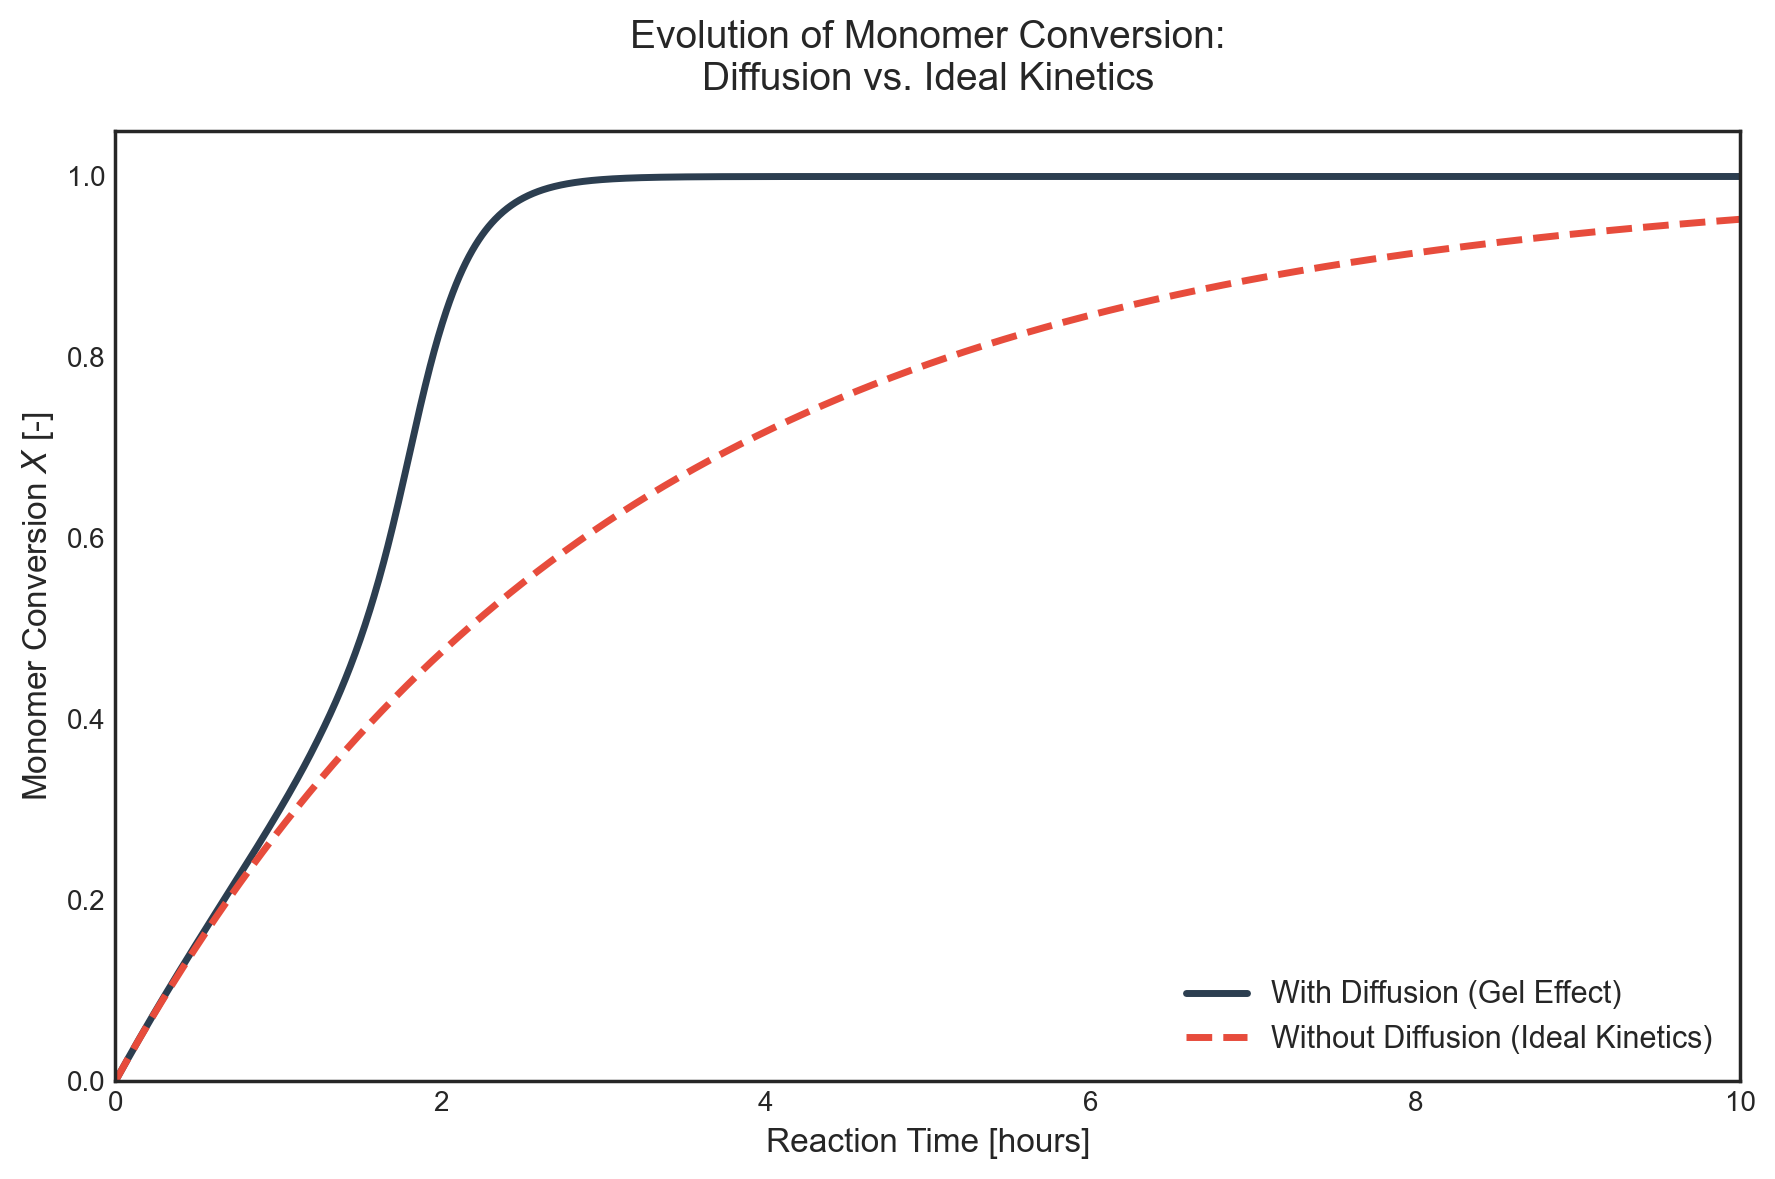

In [27]:
t_span_task2 = (0, 10 * 3600)

sol_nodiff = solve_ivp(reactor_ode, t_span_task2, y0, args=(False,), method='Radau', t_eval=t_smooth)

# conversion for the ideal case
X_nodiff = (M_0 - sol_nodiff.y[1]) / M_0

fig, ax = plt.subplots(figsize=(9, 6))

ax.plot(sol_diff.t / 3600, X_diff, label='With Diffusion (Gel Effect)', color='#2c3e50', linewidth=2.5)
ax.plot(sol_nodiff.t / 3600, X_nodiff, label='Without Diffusion (Ideal Kinetics)', color='#e74c3c', linestyle='--', linewidth=2.5)

ax.set_xlabel('Reaction Time [hours]')
ax.set_ylabel('Monomer Conversion $X$ [-]')
ax.set_title('Evolution of Monomer Conversion:\nDiffusion vs. Ideal Kinetics', pad=15)
ax.set_xlim(0, 10) 
ax.set_ylim(0, 1.05)


ax.legend(frameon=False) 
ax.grid(False)           
plt.tight_layout()
plt.show()

***Results***

In the ideal scenario (red dashed line), $k_t$ remains constant, and the reaction follows a predictable, gradual curve. In reality (blue line), the growing polymer chains drastically increase the mixture's viscosity.   
Auto-Acceleration: This high viscosity physically traps the long active chains, hindering their ability to find each other and terminate ($k_t$ drops). Because initiation continues but termination stalls, active radicals accumulate rapidly, causing the reaction rate to explode (auto-acceleration) between 1 and 2 hours.   
 
Neglecting diffusion limitations entirely fails to predict this thermal and kinetic spike, which is exactly why industrial bulk/solution polymerizations pose severe thermal runaway risks if not properly modeled and cooled

### 3:  Instantaneous Chain Length Averages & PDI


Case A (Disproportionation): $\beta = 0$. The distribution is governed by $\gamma$.

 $\gamma = \frac{k_{td}[R^\bullet]}{k_p[M]} + \frac{k_{fm}}{k_p}$

Case B (Combination): $\gamma = 0$. Two active chains merge into one dead chain, producing longer average chains and a tighter distribution.

$\beta = \frac{k_{tc}[R^\bullet]}{k_p[M]}$

Case C (Chain Transfer): $k_{fm} = 0.01 k_p$. Transfer to monomer dominates the termination kinetics ($\gamma \approx 0.01$). This bounds the number average chain length ($\bar{n}_N$) at roughly 100, keeping the polymer properties highly immune to the gel effect. 

$\alpha = \beta + \gamma$


Instantaneous Number Chain Length Distribution: The fraction of dead chains of exactly length $n$ formed at a given instant:$$f_N(n) = \frac{\alpha}{(1+\alpha)^n} \left[ \frac{\gamma + \frac{1}{2}(n-1)\beta\alpha}{\gamma + \frac{1}{2}\beta} \right]$$


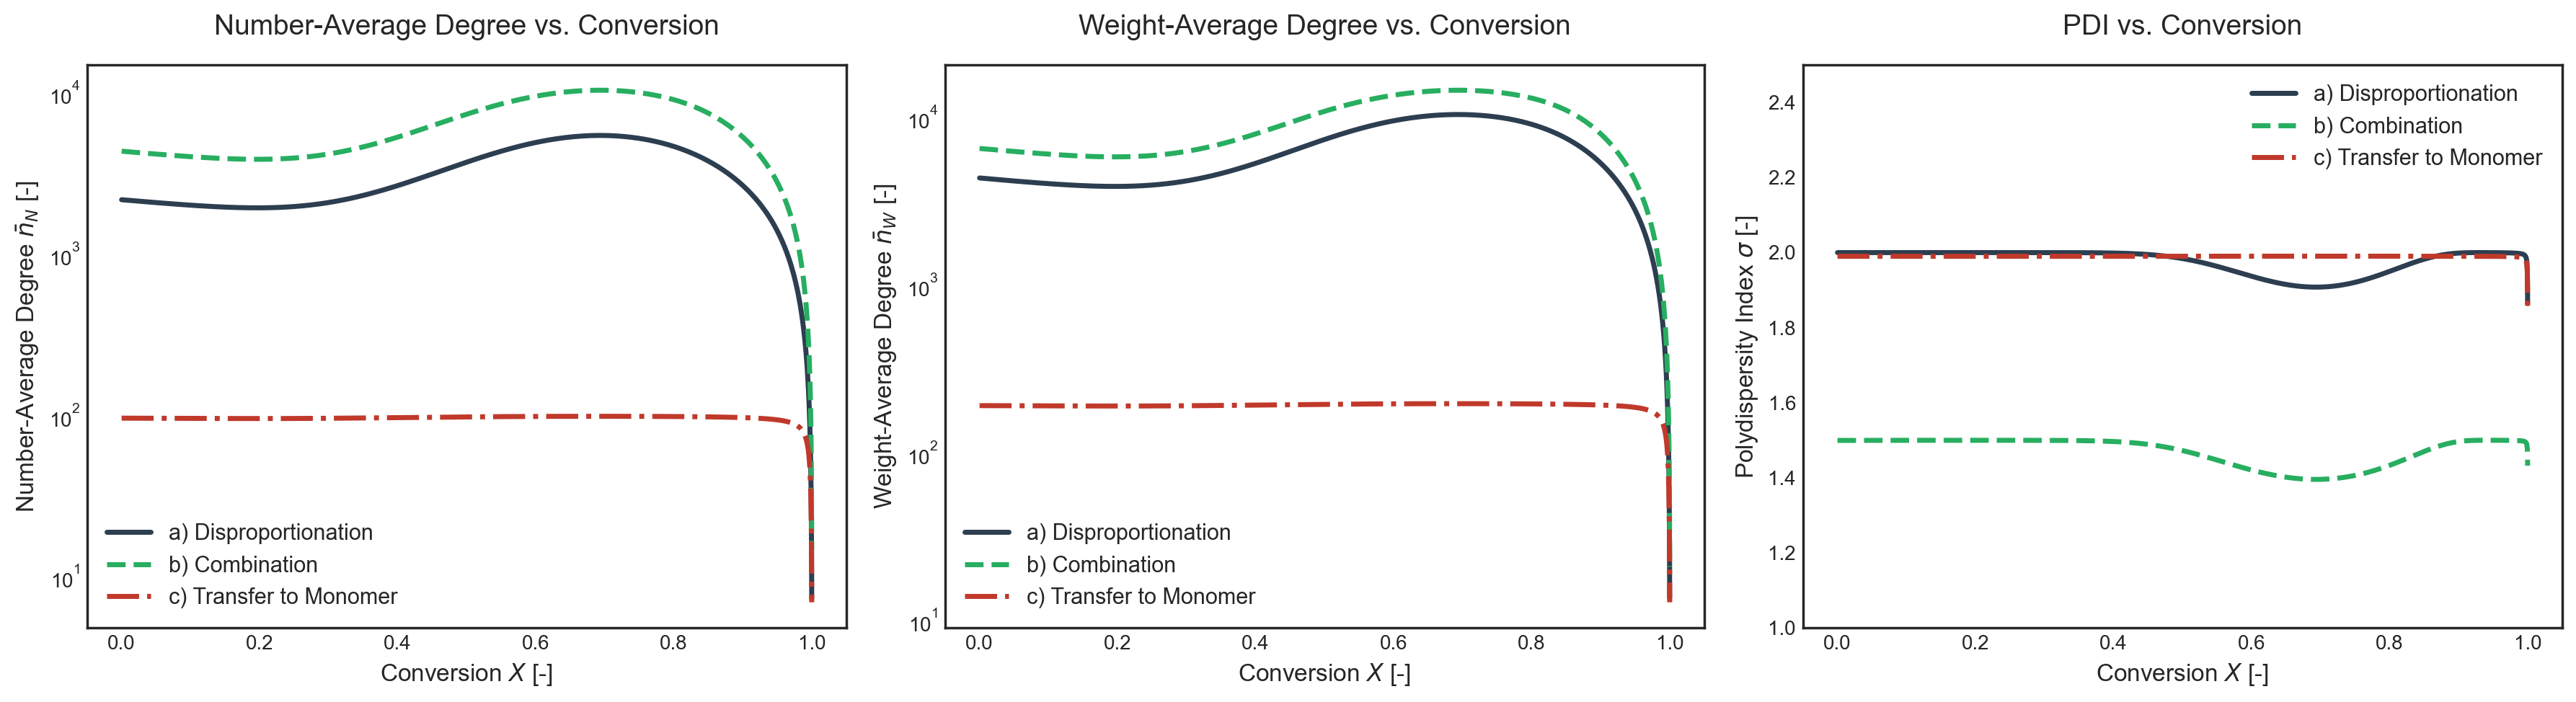

In [28]:
# extract continuous I and M
I_smooth = sol_diff.sol(t_smooth)[0]
M_smooth = sol_diff.sol(t_smooth)[1]
X_smooth = (M_0 - M_smooth) / M_0

# prevent division by zero as Monomer depletes,
valid = M_smooth > 0.001
I_v = I_smooth[valid]
M_v = M_smooth[valid]
X_v = X_smooth[valid]

w_p_v = (X_v * mass_M_0) / mass_total
k_p_v = 1.0 / ((1.0/k_p0) + (np.exp(C_eta * w_p_v) / k_pD0))
k_t_v = 1.0 / ((1.0/k_t0) + (np.exp(C_eta * w_p_v) / k_tD0)) + C_RD * k_p_v * (1.0 - w_p_v)

R_dot_v = np.sqrt((2 * f * k_d * I_v) / k_t_v)


# Case A: Disproportionation only
beta_A = np.zeros_like(M_v)
gamma_A = (k_t_v * R_dot_v) / (k_p_v * M_v)

# Case B: Combination only
beta_B = (k_t_v * R_dot_v) / (k_p_v * M_v)
gamma_B = np.zeros_like(M_v)

# Case C: Transfer to Monomer (k_fm = 0.01 * k_p) -> (k_fm / k_p = 0.01)
beta_C = np.zeros_like(M_v)
gamma_C = 0.01 + (k_t_v * R_dot_v) / (k_p_v * M_v)

# compute moments up to 30,000 units
def calc_numerical_averages(beta_arr, gamma_arr, n_max=30000):
    n = np.arange(1, n_max + 1)
    
    n_N = np.zeros_like(beta_arr)
    n_W = np.zeros_like(beta_arr)
    sigma = np.zeros_like(beta_arr)
    
    for i in range(len(beta_arr)):
        b = beta_arr[i]
        g = gamma_arr[i]
        a = b + g
        
        # Prevent division by zero errors at the very edges
        if a <= 0 or (g + 0.5 * b) <= 0:
            continue
            
        # Calculate the distribution up to n_max
        term1 = np.exp(np.log(a) - n * np.log1p(a))
        term2 = (g + 0.5 * (n - 1) * b * a) / (g + 0.5 * b)
        f_N = term1 * term2
        
        # Calculate the moments from the array
        mu0 = np.sum(f_N)
        mu1 = np.sum(n * f_N)
        mu2 = np.sum((n**2) * f_N)
        
        # Calculate averages from the moments
        n_N[i] = mu1 / mu0
        n_W[i] = mu2 / mu1
        sigma[i] = n_W[i] / n_N[i]
        
    return n_N, n_W, sigma

nN_A, nW_A, sig_A = calc_numerical_averages(beta_A, gamma_A)
nN_B, nW_B, sig_B = calc_numerical_averages(beta_B, gamma_B)
nN_C, nW_C, sig_C = calc_numerical_averages(beta_C, gamma_C)




# 5. Plotting
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(18, 5))

# Updated to a more visible dash-dot for the third line and a cohesive palette
linestyles = ['-', '--', '-.']
colors = ['#2c3e50', '#27ae60', '#c0392b']

# Plot Number Average
ax1.plot(X_v, nN_A, label='a) Disproportionation', color=colors[0], linestyle=linestyles[0], linewidth=2.5)
ax1.plot(X_v, nN_B, label='b) Combination', color=colors[1], linestyle=linestyles[1], linewidth=2.5)
ax1.plot(X_v, nN_C, label='c) Transfer to Monomer', color=colors[2], linestyle=linestyles[2], linewidth=2.5)
ax1.set_yscale('log')
ax1.set_xlabel('Conversion $X$ [-]')
ax1.set_ylabel(r'Number-Average Degree $\bar{n}_N$ [-]')
ax1.set_title(r'Number-Average Degree vs. Conversion', pad=15)
ax1.legend(frameon=False)
ax1.grid(False)

# Plot Weight Average
ax2.plot(X_v, nW_A, label='a) Disproportionation', color=colors[0], linestyle=linestyles[0], linewidth=2.5)
ax2.plot(X_v, nW_B, label='b) Combination', color=colors[1], linestyle=linestyles[1], linewidth=2.5)
ax2.plot(X_v, nW_C, label='c) Transfer to Monomer', color=colors[2], linestyle=linestyles[2], linewidth=2.5)
ax2.set_yscale('log')
ax2.set_xlabel('Conversion $X$ [-]')
ax2.set_ylabel(r'Weight-Average Degree $\bar{n}_W$ [-]')
ax2.set_title(r'Weight-Average Degree vs. Conversion', pad=15)
ax2.legend(frameon=False)
ax2.grid(False)

# Plot PDI
ax3.plot(X_v, sig_A, label='a) Disproportionation', color=colors[0], linestyle=linestyles[0], linewidth=2.5)
ax3.plot(X_v, sig_B, label='b) Combination', color=colors[1], linestyle=linestyles[1], linewidth=2.5)
ax3.plot(X_v, sig_C, label='c) Transfer to Monomer', color=colors[2], linestyle=linestyles[2], linewidth=2.5)
ax3.set_xlabel('Conversion $X$ [-]')
ax3.set_ylabel(r'Polydispersity Index $\sigma$ [-]')
ax3.set_title(r'PDI vs. Conversion', pad=15)
ax3.set_ylim(1.0, 2.5)
ax3.legend(frameon=False)
ax3.grid(False)

plt.tight_layout()
plt.show()

***Results***

X=0.4 to 0.8. The swell in chain lengths for both disproportionation and combination is the gel effect in action. As the reaction mixture becomes viscous, it  traps the long active radicals and prevents them from finding each other to terminate. Because radicals survive longer, they grow much longer.

X > 0.9 monomer starvation. radicals have no unreacted monomer left to consume. Propagation stalls out causing new chain lengths to diminish.

Combination produces chains twice as long as disproportionation because two active radicals merge into a single dead chain. This merging process  narrows the distribution of chain lengths, driving PDI down to exactly 3/2 for combination, while disproportionation hovers at 2.

When chain transfer to monomer dominates, the average chain length flatlines near 100 units. Because the monomer is not hindered by the high viscosity, the termination rate stays steady.

The slight dip in PDI during the gel effect is a numerical artifact caused by the assignment constraint to cap chain lengths at 30,000 units. This hard limit amputates the long-chain tail of the distribution, which shrinks weight-average ($\bar{n}_W$) and forces the calculated PDI ($\bar{n}_W / \bar{n}_N$) to artificially drop


### 4) Cumulative number and weight CLD

Instantaneous properties describe the chains forming at one specific split-second (a snapshot). Cumulative properties describe the physical mixture of all chains that have accumulated in the reactor from $t=0$ up to that point (a moving average).  
 
During the auto-acceleration phase, the restricted termination causes instantaneous chain lengths to spike. However, the cumulative averages ($\bar{n}_N^c$, $\bar{n}_W^c$) rise much more gradually. This is because the reactor already contains a vast number of shorter chains produced earlier in the reaction, which drag the average down.   

The cumulative distribution $f_N^c(n)$ is the integral of the instantaneous distribution $f_N(n)$ weighted by the rate of dead chain production $\frac{dP}{dt}$, divided by the total number of chains $P(t)$ 

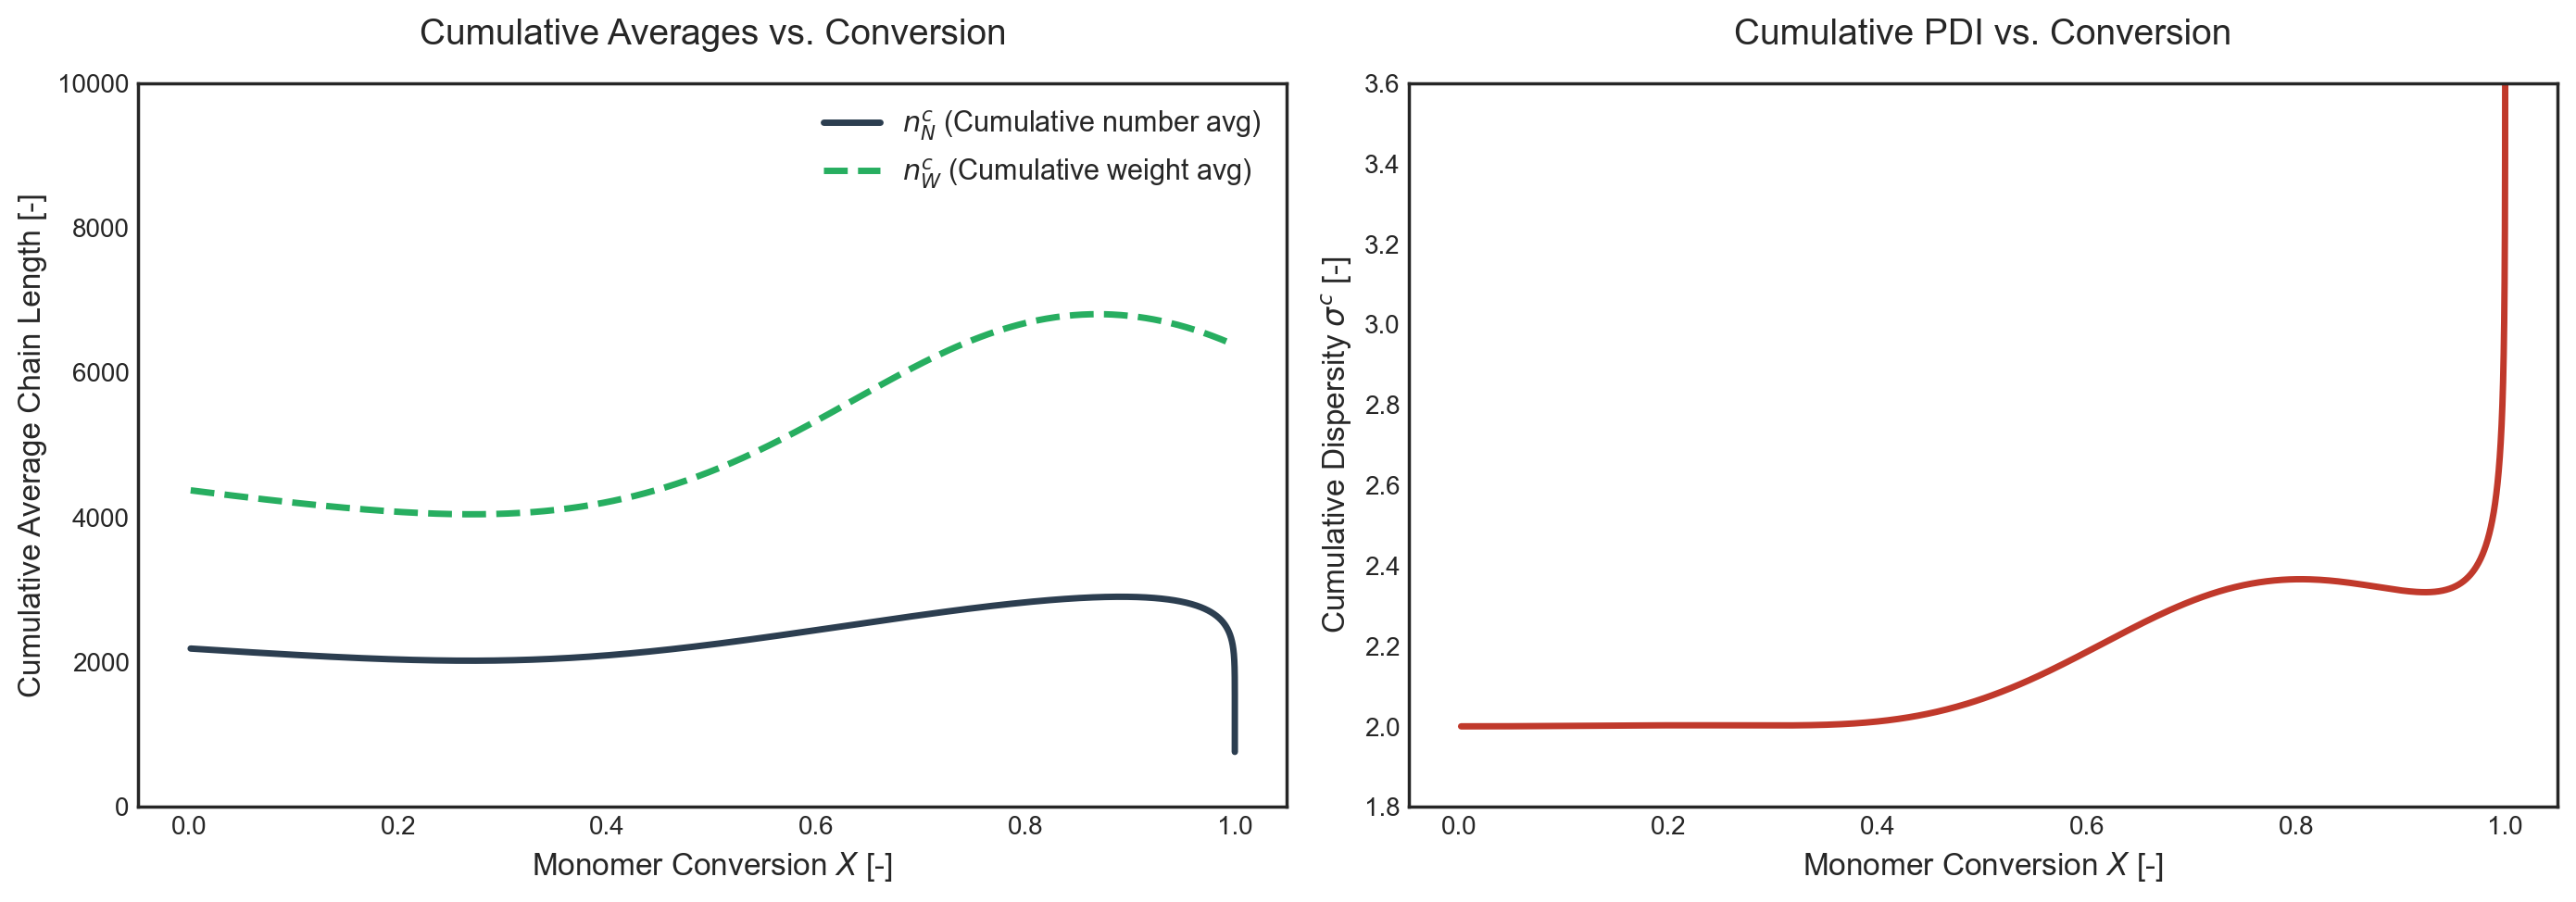

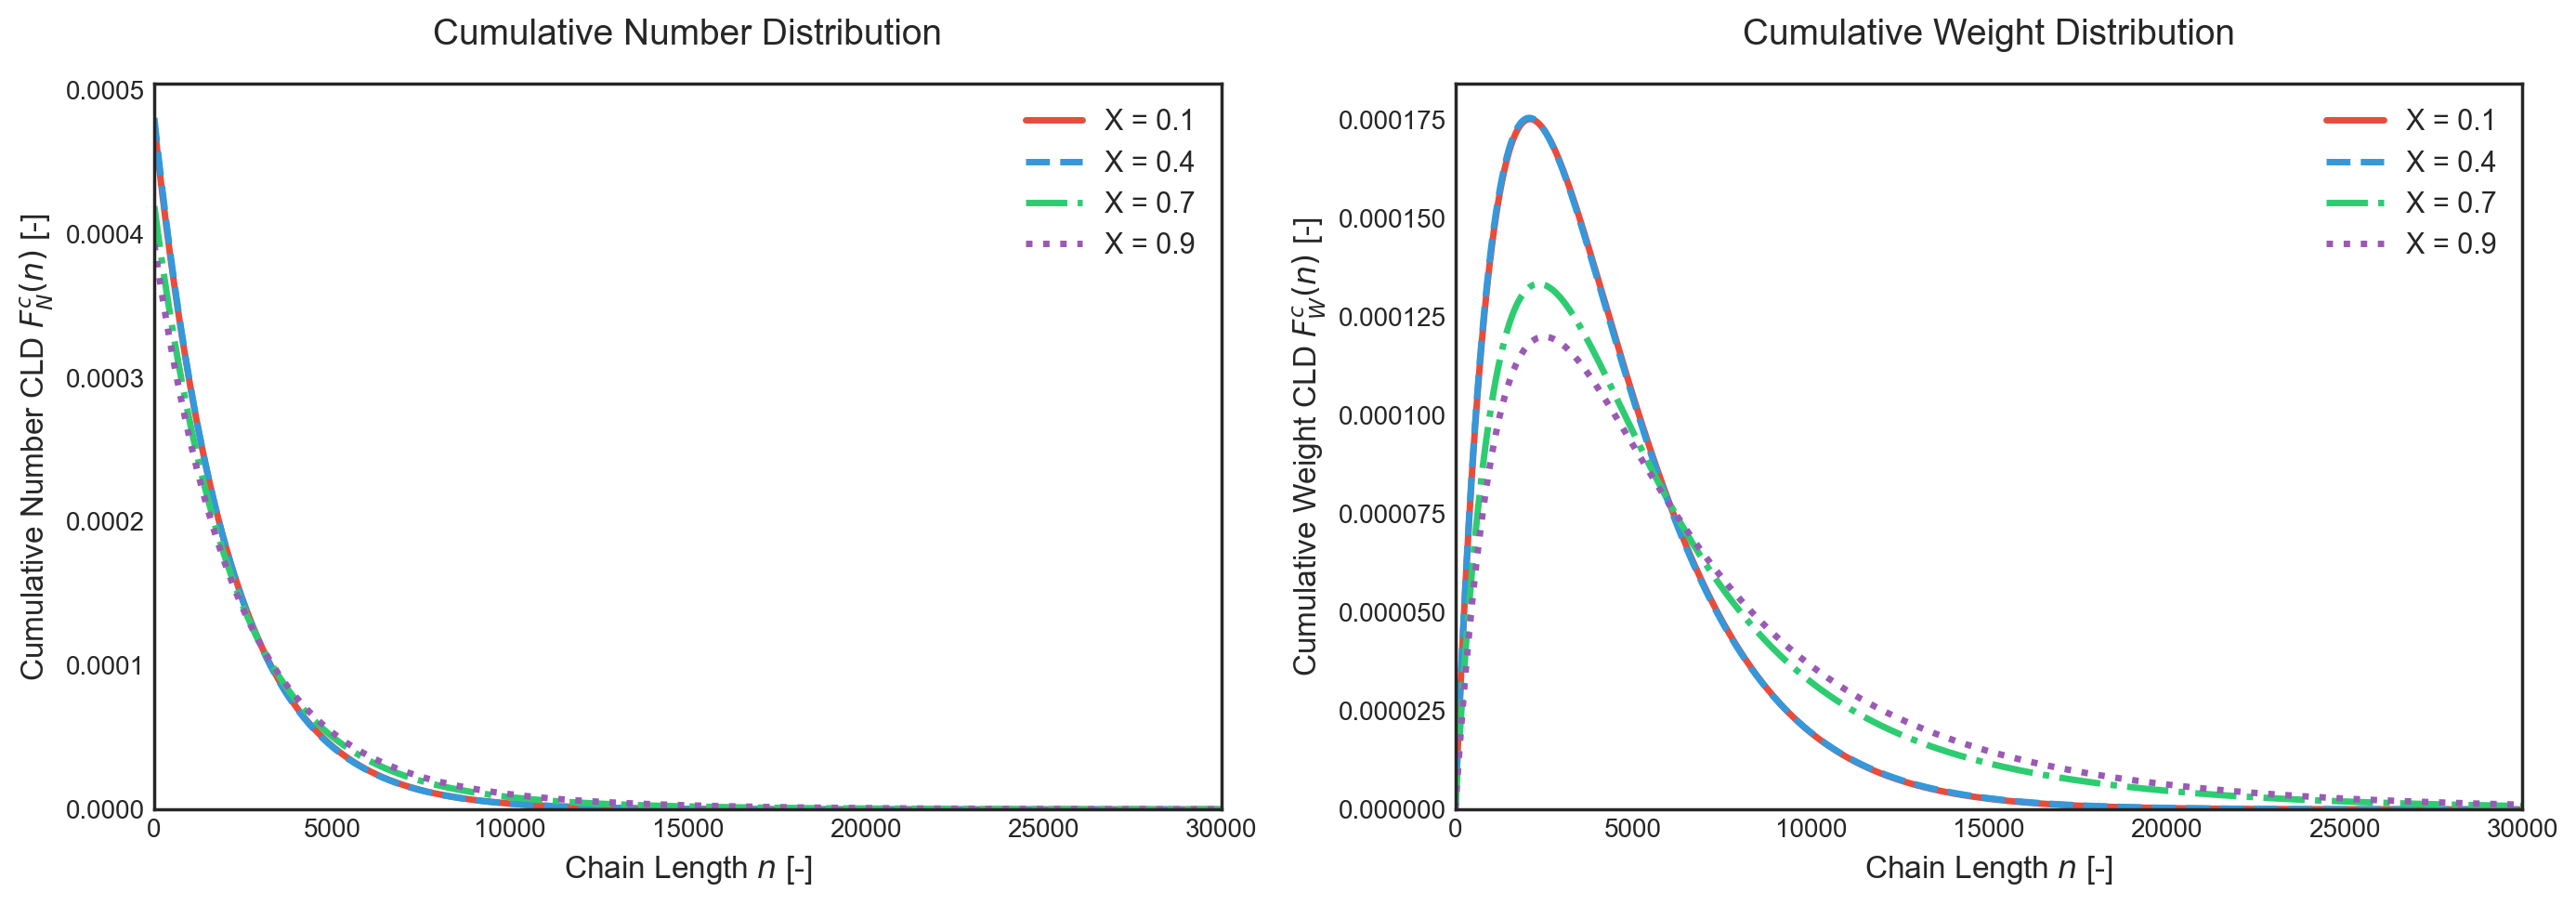

In [29]:
#Case A: Disproportionation dominates

import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import cumulative_trapezoid


t_v = t_smooth
I_v = sol_diff.sol(t_v)[0]
M_v = sol_diff.sol(t_v)[1]
X_v = (M_0 - M_v) / M_0

# Recalculate kinetics over time
w_p_v = (X_v * mass_M_0) / mass_total
k_p_v = 1.0 / ((1.0/k_p0) + (np.exp(C_eta * w_p_v) / k_pD0))
k_t_v = 1.0 / ((1.0/k_t0) + (np.exp(C_eta * w_p_v) / k_tD0)) + C_RD * k_p_v * (1.0 - w_p_v)

R_dot_v = np.sqrt((2 * f * k_d * I_v) / k_t_v)
R_p_v = k_p_v * M_v * R_dot_v

# For A: beta = 0
gamma_v = (k_t_v * R_dot_v) / (k_p_v * M_v)
dP_dt_v = R_p_v * gamma_v

# Since the ODE didn't track moments, we integrate the instantaneous rates here.
nN_inst = 1.0 / gamma_v
nW_inst = 2.0 / gamma_v

dmu0_dt = dP_dt_v                     # Rate of forming total chains
dmu1_dt = nN_inst * dP_dt_v           # Rate of adding monomer units to dead chains
dmu2_dt = nW_inst * dmu1_dt           # Rate of 2nd moment generation

# Integrate rates over time to get cumulative totals
mu0_P = cumulative_trapezoid(dmu0_dt, x=t_v, initial=0)
mu1_P = cumulative_trapezoid(dmu1_dt, x=t_v, initial=0)
mu2_P = cumulative_trapezoid(dmu2_dt, x=t_v, initial=0)

# Filter out t=0 to avoid division by zero when calculating averages
valid = mu0_P > 1e-10
X_cum = X_v[valid]

nN_cum = mu1_P[valid] / mu0_P[valid]
nW_cum = mu2_P[valid] / mu1_P[valid]
sig_cum = nW_cum / nN_cum

# PLOT
fig1, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# 1. Cumulative Average Chain Lengths
ax1.plot(X_cum, nN_cum, label='$n_N^c$ (Cumulative number avg)', color='#2c3e50', linestyle='-', linewidth=2.5)
ax1.plot(X_cum, nW_cum, label='$n_W^c$ (Cumulative weight avg)', color='#27ae60', linestyle='--', linewidth=2.5)
ax1.set_xlabel('Monomer Conversion $X$ [-]')
ax1.set_ylabel('Cumulative Average Chain Length [-]')
ax1.set_title('Cumulative Averages vs. Conversion', pad=15)
ax1.set_ylim(0, 10000)
ax1.legend(frameon=False) # Removed legend box
ax1.grid(False)           # Removed grid

# 2. Cumulative Polydispersity Index
ax2.plot(X_cum, sig_cum, color='#c0392b', linestyle='-', linewidth=2.5)
ax2.set_xlabel('Monomer Conversion $X$ [-]')
ax2.set_ylabel(r'Cumulative Dispersity $\sigma^c$ [-]')
ax2.set_title('Cumulative PDI vs. Conversion', pad=15)
ax2.set_ylim(1.8, 3.6)
ax2.grid(False)           # Removed grid

plt.tight_layout()
plt.show()


# PART B: Plotting the Cumulative Distributions at Target Conversions
n_chain = np.arange(1, 30001)

fig2, (ax3, ax4) = plt.subplots(1, 2, figsize=(14, 5))

# Using the 4-color palette from earlier tasks
linestyles = ['-', '--', '-.', ':']
colors = ['#e74c3c', '#3498db', '#2ecc71', '#9b59b6'] 

for i, target_X in enumerate(target_conversions):
    # Find the index in our smooth array closest to the target conversion
    idx = (np.abs(X_v - target_X)).argmin()
    
    t_sub = t_v[:idx+1]
    gamma_sub = gamma_v[:idx+1]
    dP_dt_sub = dP_dt_v[:idx+1]
    
    # 2D array to hold the rates of production
    fN_rate_matrix = np.zeros((len(t_sub), len(n_chain)))
    
    for k in range(len(t_sub)):
        g = gamma_sub[k]
        if g > 0:
            f_N_inst = g / (1.0 + g)**n_chain
            fN_rate_matrix[k, :] = f_N_inst * dP_dt_sub[k]
            
    # Integrate numerically over the time axis 
    fN_cum_integral = np.trapezoid(fN_rate_matrix, x=t_sub, axis=0)

    
    # Divide by total chains produced up to this point
    P_total = mu0_P[idx]
    fN_cum = fN_cum_integral / P_total
    
    # Calculate cumulative weight distribution
    n_N_c_target = mu1_P[idx] / mu0_P[idx]
    fW_cum = (n_chain * fN_cum) / n_N_c_target
    
    ax3.plot(n_chain, fN_cum, label=f'X = {target_X:.1f}', 
             color=colors[i], linestyle=linestyles[i], linewidth=2.5)
    ax4.plot(n_chain, fW_cum, label=f'X = {target_X:.1f}', 
             color=colors[i], linestyle=linestyles[i], linewidth=2.5)

# Formatting Cumulative Number Distribution
ax3.set_xlim(0, 30000)
ax3.set_ylim(bottom=0)
ax3.set_xlabel('Chain Length $n$ [-]')
ax3.set_ylabel(r'Cumulative Number CLD $F_N^c(n)$ [-]')
ax3.set_title('Cumulative Number Distribution', pad=15)
ax3.legend(frameon=False)
ax3.grid(False)

# Formatting Cumulative Weight Distribution
ax4.set_xlim(0, 30000)
ax4.set_ylim(bottom=0)
ax4.set_xlabel('Chain Length $n$ [-]')
ax4.set_ylabel(r'Cumulative Weight CLD $F_W^c(n)$ [-]')
ax4.set_title('Cumulative Weight Distribution', pad=15)
ax4.legend(frameon=False)
ax4.grid(False)

plt.tight_layout()
plt.show()

The cumulative averages ($\bar{n}_N^c$ and $\bar{n}_W^c$) rise much more gradually between $X=0.4$ and $X=0.8$. The shorter chains produced early in the reaction act as a buffer, smoothing out.
The cumulative PDI steadily climbs well above the ideal 2.0 as conversion increases, ultimately spiking at the very end of the reaction.   Because the reactor pools together short chains (from the beginning and the monomer-starved end) and ultra-long chains (from the gel effect), the final physical mixture becomes highly polydisperse.   

In the weight distribution graph, the tail broadens as conversion shifts from 0.4 to 0.9. this is due to the gel-effect-produced chains accumulating in the tank and dragging the weight-average upwards over time.   

DISCLAIMER:

AI was used to generate all the plots and to smoothen code.